### __Anna Kaczyńska, Kamila Mosińska__
# PROJECT 3: STIRRED (NOT SHAKEN)
-----

### ABSTRACT

### INTRODUCTION
--------

## EXERCISE 1:
### ODE SOLVER
### PART 1

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [111]:
class ode_solver:

    def __init__(self, func, params, h, y0, t0, tf, method='euler'):
        self.f = func
        self.params = params
        self.h = h
        self.y0 = y0
        self.t0 = t0
        self.tf = tf
        self.method = method
        self.Y = []
        self.T = []

    def euler(self, t, y, h):
        return self.h * self.f(t, y, self.params)

    def rk2(self, t, y, h):
        k1 = self.h * self.f(t, y, self.params)
        k2 = self.h * self.f(t + h/2, y + 1/2*k1, self.params)
        return k2

    def rk4(self, t, y, h):
        k1 = self.h * self.f(t, y, self.params)
        k2 = self.h * self.f(t + h/2, y + 1/2*k1, self.params)
        k3 = self.h * self.f(t + h/2, y + 1/2*k2, self.params)
        k4 =self.h * self.f(t + h, y + k3, self.params)
        return 1/6 * (k1 + 2*k2 + 2*k3 + k4)
    
    def solver(self):
        self.Y = []
        self.T = []
        self.Y.append(self.y0.copy())
        self.T.append(self.t0)
        h = self.h
        t0 = self.t0
        tf = self.tf
        method = self.method
        y_old = self.y0

        for t in np.arange(t0, tf, h):
            if method == 'euler':
                y_new = y_old + self.euler(t,y_old,h)
            elif method == 'rk2':
                y_new = y_old + self.rk2(t,y_old,h)
            elif method == 'rk4':
                y_new = y_old + self.rk4(t,y_old,h)

            y_old = y_new
            self.Y.append(y_old)
            self.T.append(t + h)

        Y = np.array(self.Y)
        T = np.array(self.T)

        return Y, T

### PART 2

In [112]:
def C_concentration(t, C, params):

    n, tau, C_in = params

    dCdt = np.zeros(n)
    dCdt[0] = (n/tau) * (C_in - C[0])

    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    return dCdt

results = {}
for n in [1, 2, 3]:
    params = (n, 2, 0)

    C0 = np.zeros(n)
    C0[0] = 1
    y0 = C0

    solve = ode_solver(C_concentration, params, 0.1, C0, 0, 10, method = 'rk4')
    Y, T = solve.solver()

    results[n] = (Y,T)


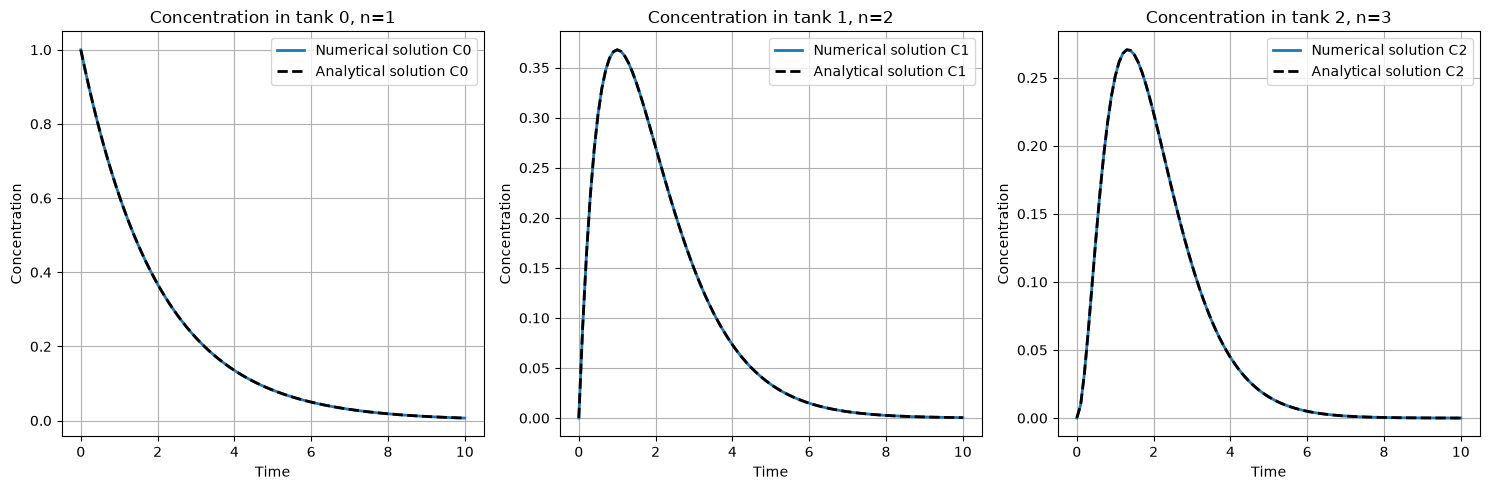

In [49]:
tau = 2

Y_values = [results[n][0] for n in [1, 2, 3]]
T_values = [results[n][1] for n in [1, 2, 3]]

C_exact = [
    np.exp(-T_values[0]/tau),
    (2*T_values[1]/tau) * np.exp(-2*T_values[1]/tau),
    (9*T_values[2]**2/(2*tau**2)) * np.exp(-3*T_values[2]/tau)
]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i in range(3):
    ax[i].plot(T_values[i], Y_values[i][:,i], # change Y_values[i][:,i] to Y_values[i] if you want to display all the solutions
               label=f'Numerical solution C{i}', linewidth=2)

    ax[i].plot(T_values[i], C_exact[i], '--',
               label=f'Analytical solution C{i}',
               color='black', linewidth=2)

    ax[i].set_xlabel("Time")
    ax[i].set_ylabel("Concentration")
    ax[i].set_title(f"Concentration in tank {i}, n={i+1}")
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

### PART 3

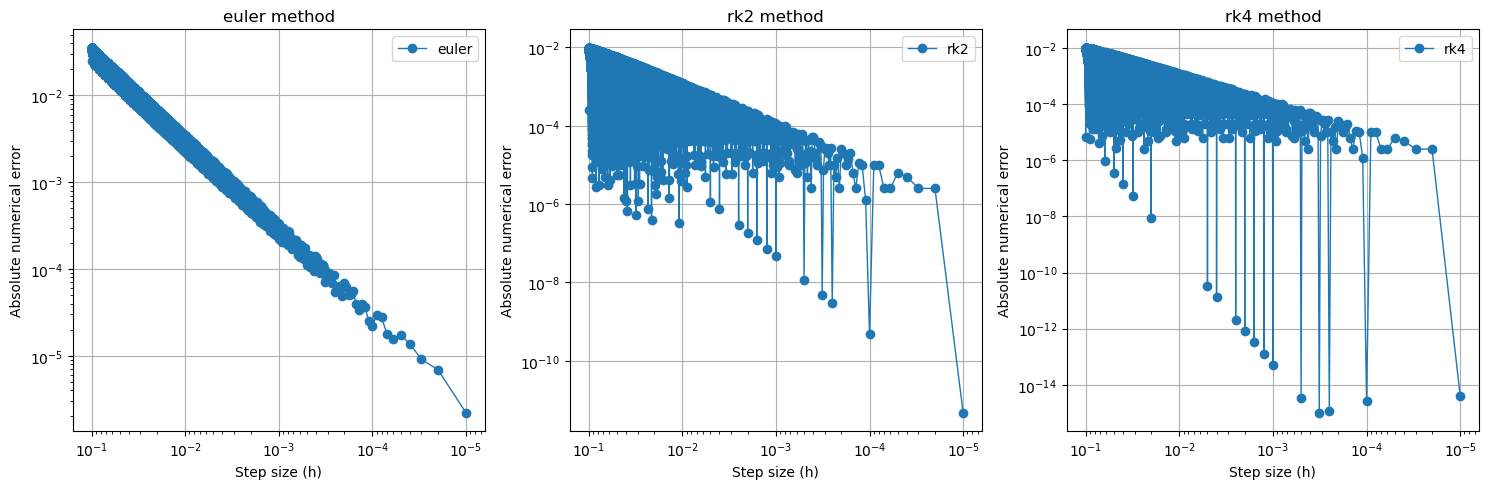

In [5]:
# for n = 3

h = np.linspace(0.1, 0.00001, 10000)
t_exact = 1
C_exact_3 = (9*t_exact**2/(2*tau**2)) * np.exp(-3*t_exact/tau)

methods = ['euler', 'rk2', 'rk4']
errors = {}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

for i, method in enumerate(methods):
    errors[method] = []

    for step in h:
        solve = ode_solver(
            C_concentration, (3, 2, 0), step,
            C0, 0, 1, method=method
        )

        Y, T = solve.solver()
        error = abs(C_exact_3 - Y[-1, 2])
        errors[method].append(error)

    ax[i].loglog(h, errors[method], 'o-', label=method, linewidth = 1)
    ax[i].invert_xaxis() # to order the x axis decreasingly
    ax[i].set_xlabel('Step size (h)')
    ax[i].set_ylabel('Absolute numerical error')
    ax[i].set_title(f'{method} method')
    ax[i].legend()
    ax[i].grid()

plt.tight_layout()
plt.show()

## TO DO: 

Does the numerical error scale as expected for Euler, RK2, and RK4?

-----
## EXERCISE 2:
### FITTING CSTR MODEL TO CFD MODEL
### PART 1

In [113]:
healthy_rect_1s = pd.read_csv('data/Healthy_rect_1s.csv')
healthy_rect_1s

,Time,Concentration
0,0.00,0.000000e+00
1,0.02,0.000000e+00
2,0.04,0.000000e+00
3,0.06,0.000000e+00
4,0.08,0.000000e+00
...,...,...
246,4.92,8.620000e-06
247,4.94,4.980000e-06
248,4.96,2.020000e-06
249,4.98,2.510000e-08


In [114]:
M_inj = 83.333

time = healthy_rect_1s['Time'].to_numpy()
C_out = healthy_rect_1s['Concentration'].to_numpy()

integral = np.trapezoid(C_out,time)
q = (60/1000)* (M_inj / integral)
print(q)

5.005983664163233


### PART 2

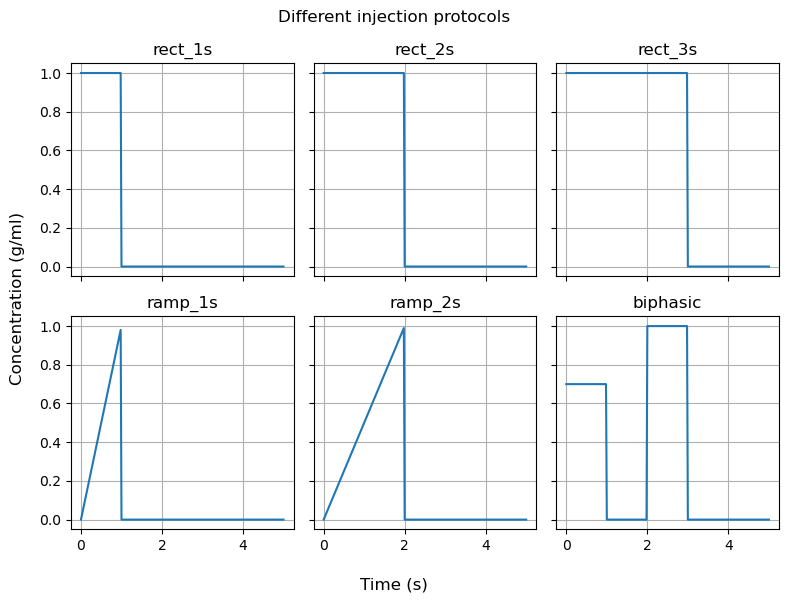

In [115]:
def c_inj(t,ti=np.array([0,1.,1.,2.,2.,3.,3.]),qi=np.array([0,0,0,0,0,0,0]),ci=np.array([1,1,0,0,0,0,0])):
    return np.interp(t,ti,ci),np.interp(t,ti,qi)

rect_1s = c_inj(time)[0]
rect_2s = c_inj(time, ci=np.array([1,1,1,1,0,0,0]))[0]
rect_3s = c_inj(time, ci=np.array([1,1,1,1,1,1,0]))[0]
ramp_1s = c_inj(time, ci=np.array([0,1,0,0,0,0,0]))[0]
ramp_2s = c_inj(time, ci=np.array([0,0.5,0.5,1,0,0,0]))[0]
biphasic = c_inj(time, ci=np.array([0.7,0.7,0,0,1,1,0]))[0]

protocols = [rect_1s, rect_2s, rect_3s, ramp_1s, ramp_2s, biphasic]
names = ['rect_1s', 'rect_2s', 'rect_3s','ramp_1s', 'ramp_2s', 'biphasic']

fig, ax = plt.subplots(2, 3, figsize=(8,6), sharex=True, sharey = True)

for a, protocol, name in zip(ax.flat, protocols, names):
    a.plot(time, protocol)
    a.set_title(name)
    a.grid()

fig.supxlabel('Time (s)')
fig.supylabel('Concentration (g/ml)')
plt.suptitle('Different injection protocols')
plt.tight_layout()
plt.show()

### PART 3

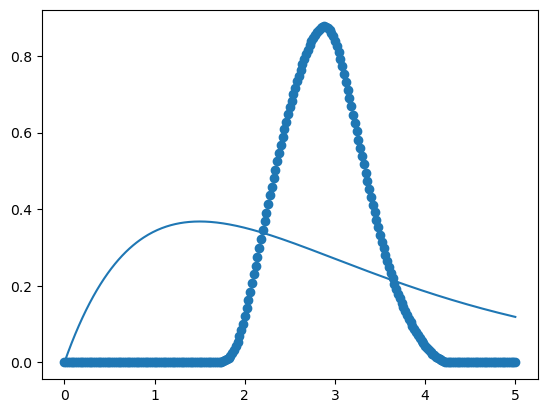

In [116]:
n_containers = 10
tau = 15
params = (n_containers, tau, 0)

C0 = np.zeros(n_containers)
C0[0] = 1
y0 = C0
solve = ode_solver(C_concentration, params, 0.01, C0, 0, 5, method = 'rk4')
Y, T = solve.solver()

# we need to match these
plt.scatter(time, C_out)
plt.plot(T,Y[:,1])
plt.show()

In [117]:
def C_concentration(t, C, params):

    n, tau, C_in = params

    C_in_t = np.interp(t, time, C_in)

    dCdt = np.zeros(n)
    dCdt[0] = (n/tau) * (C_in_t - C[0])

    for i in range(1, n):
        dCdt[i] = (n/tau) * (C[i-1] - C[i])

    return dCdt

In [118]:
results = []

for n in range(1, 21):

    def simulation(time, tau):

        params = (n, tau, rect_1s)

        C0 = np.zeros(n)

        solve = ode_solver(
            C_concentration,
            params,
            0.01,
            C0,
            0,
            5,
            method='rk4'
        )

        Y, T = solve.solver()

        return np.interp(time, T, Y[:, -1])

    popt, pcov = curve_fit(
        simulation,
        time,
        C_out,
        p0=[15],
        bounds=([0.001], [1000])
    )

    tau_opt = popt[0]
    C_sim = simulation(time, tau_opt)

    SSR = np.sum((C_out - C_sim)**2)

    results.append((n, tau_opt, SSR))

In [119]:
results = np.array(results)

best_idx = np.argmin(results[:, 2])

best_n = int(results[best_idx, 0])
best_tau = results[best_idx, 1]
best_SSR = results[best_idx, 2]

print("Best number of compartments:", best_n)
print("Best tau:", best_tau)
print("Best SSR:", best_SSR)

Best number of compartments: 14
Best tau: 2.3947312717268963
Best SSR: 3.5183041946316918


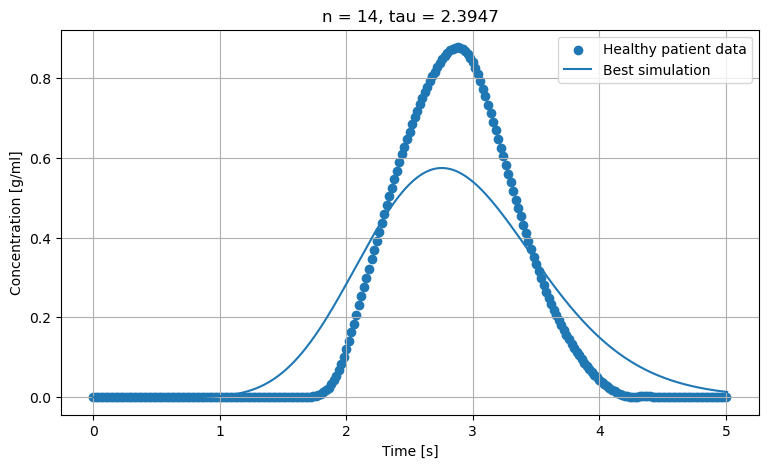

In [121]:
params = (best_n, best_tau, rect_1s)

C0 = np.zeros(best_n)

solve = ode_solver(
    C_concentration,
    params,
    0.01,
    C0,
    0,
    5.01,
    method='rk4'
)

Y, T = solve.solver()

plt.figure(figsize=(9, 5))

plt.scatter(time, C_out, label='Healthy patient data')
plt.plot(T, Y[:, -1], label='Best simulation')

plt.xlabel('Time [s]')
plt.ylabel('Concentration [g/ml]')
plt.title(f'n = {best_n}, tau = {best_tau:.4f}')
plt.legend()
plt.grid()
plt.show()

### PART 4

In [122]:
healthy_rect_2s = pd.read_csv('data/Healthy_rect_2s.csv')
healthy_ramp_2s = pd.read_csv('data/Healthy_ramp_2s.csv')
healthy_biphasic = pd.read_csv('data/Healthy_biphasic.csv')

time_rect_2s = healthy_rect_2s['Time'].to_numpy()
C_out_rect_2s = healthy_rect_2s['Concentration'].to_numpy()
time_ramp_2s = healthy_ramp_2s['Time'].to_numpy()
C_out_ramp_2s = healthy_ramp_2s['Concentration'].to_numpy()
time_biphasic = healthy_biphasic['Time'].to_numpy()
C_out_biphasic = healthy_biphasic['Concentration'].to_numpy()

datasets = {
    'rect_2s': (time_rect_2s, C_out_rect_2s, rect_2s),
    'ramp_2s': (time_ramp_2s, C_out_ramp_2s, ramp_2s),
    'biphasic': (time_biphasic, C_out_biphasic, biphasic)
}

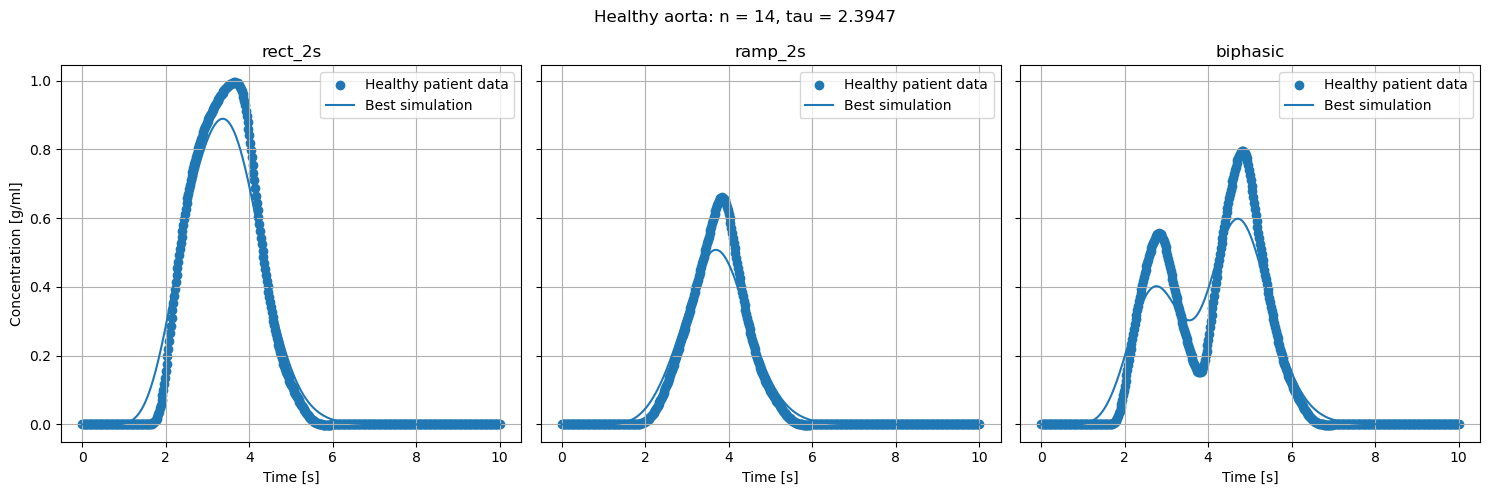

In [123]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for a, (name, (time_data, C_data, protocol)) in zip(ax, datasets.items()):

    params = (best_n, best_tau, protocol)

    C0 = np.zeros(best_n)

    solve = ode_solver(
        C_concentration,
        params,
        0.01,
        C0,
        0,
        10.01,
        method='rk4'
    )

    Y, T = solve.solver()

    a.scatter(time_data, C_data, label='Healthy patient data')
    a.plot(T, Y[:, -1], label='Best simulation')

    a.set_title(name)
    a.set_xlabel('Time [s]')
    a.grid()
    a.legend()

ax[0].set_ylabel('Concentration [g/ml]')

plt.suptitle(f'Healthy aorta: n = {best_n}, tau = {best_tau:.4f}')
plt.tight_layout()
plt.show()

#### Discuss your findings.

## EXERCISE 3:
### Aorta with aneurysm
### PART 4

In [124]:
unhealthy_rect_1s = pd.read_csv('data/Aneurysm_rect_1s.csv')
unhealthy_rect_1s

,Time,Concentration
0,0.00,0.000000
1,0.02,0.000000
2,0.04,0.000000
3,0.06,0.000000
4,0.08,0.000000
...,...,...
246,4.92,0.008076
247,4.94,0.008012
248,4.96,0.007968
249,4.98,0.007947


In [125]:
time_rect_1s = unhealthy_rect_1s['Time'].to_numpy()
C_out_rect_1s = unhealthy_rect_1s['Concentration'].to_numpy()

In [126]:
results = []

for n in range(1, 21):

    def simulation(time_rect_1s, tau):

        params = (n, tau, rect_1s)

        C0 = np.zeros(n)

        solve = ode_solver(
            C_concentration,
            params,
            0.01,
            C0,
            0,
            5.01,
            method='rk4'
        )

        Y, T = solve.solver()

        return np.interp(time_rect_1s, T, Y[:, -1])

    popt, pcov = curve_fit(
        simulation,
        time_rect_1s,
        C_out_rect_1s,
        p0=[15],
        bounds=([0.001], [1000])
    )

    tau_opt = popt[0]
    C_sim = simulation(time_rect_1s, tau_opt)

    SSR = np.sum((C_out_rect_1s - C_sim)**2)

    results.append((n, tau_opt, SSR))

In [127]:
results = np.array(results)

best_idx = np.argmin(results[:, 2])

best_n = int(results[best_idx, 0])
best_tau = results[best_idx, 1]
best_SSR = results[best_idx, 2]

print("Best number of compartments:", best_n)
print("Best tau:", best_tau)
print("Best SSR:", best_SSR)

Best number of compartments: 15
Best tau: 2.4760768954989834
Best SSR: 0.6187097257144881


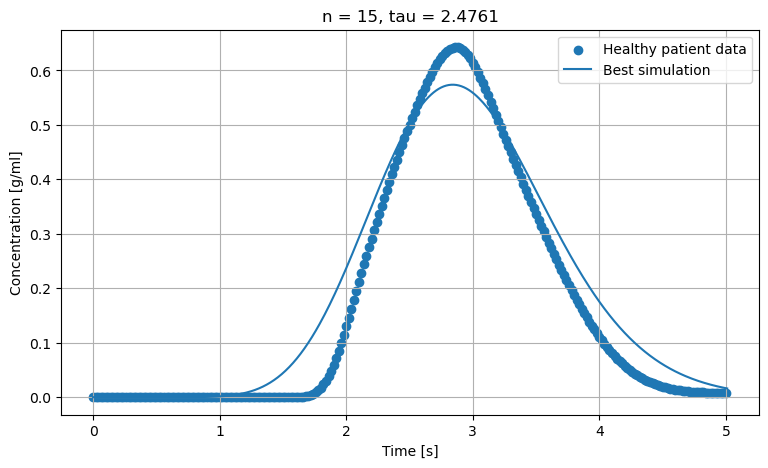

In [128]:
params = (best_n, best_tau, rect_1s)

C0 = np.zeros(best_n)

solve = ode_solver(
    C_concentration,
    params,
    0.01,
    C0,
    0,
    5.01,
    method='rk4'
)

Y, T = solve.solver()

plt.figure(figsize=(9, 5))

plt.scatter(time_rect_1s, C_out_rect_1s, label='Healthy patient data')
plt.plot(T, Y[:, -1], label='Best simulation')

plt.xlabel('Time [s]')
plt.ylabel('Concentration [g/ml]')
plt.title(f'n = {best_n}, tau = {best_tau:.4f}')
plt.legend()
plt.grid()
plt.show()

In [129]:
unhealthy_rect_2s = pd.read_csv('data/Aneurysm_rect_2s.csv')
unhealthy_ramp_2s = pd.read_csv('data/Aneurysm_ramp_2s.csv')
unhealthy_biphasic = pd.read_csv('data/Aneurysm_biphasic.csv')

time_rect_2s = unhealthy_rect_2s['Time'].to_numpy()
C_out_rect_2s = unhealthy_rect_2s['Concentration'].to_numpy()
time_ramp_2s = unhealthy_ramp_2s['Time'].to_numpy()
C_out_ramp_2s = unhealthy_ramp_2s['Concentration'].to_numpy()
time_biphasic = unhealthy_biphasic['Time'].to_numpy()
C_out_biphasic = unhealthy_biphasic['Concentration'].to_numpy()

datasets = {
    'rect_2s': (time_rect_2s, C_out_rect_2s, rect_2s),
    'ramp_2s': (time_ramp_2s, C_out_ramp_2s, ramp_2s),
    'biphasic': (time_biphasic, C_out_biphasic, biphasic)
}

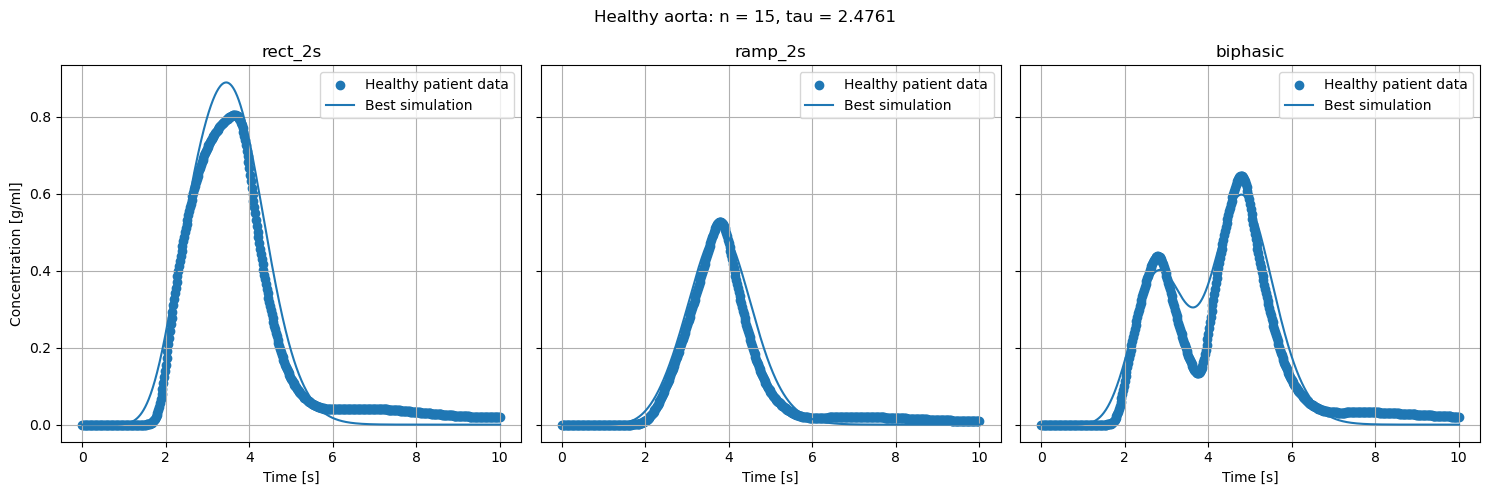

In [130]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for a, (name, (time_data, C_data, protocol)) in zip(ax, datasets.items()):

    params = (best_n, best_tau, protocol)

    C0 = np.zeros(best_n)

    solve = ode_solver(
        C_concentration,
        params,
        0.01,
        C0,
        0,
        10.01,
        method='rk4'
    )

    Y, T = solve.solver()

    a.scatter(time_data, C_data, label='Healthy patient data')
    a.plot(T, Y[:, -1], label='Best simulation')

    a.set_title(name)
    a.set_xlabel('Time [s]')
    a.grid()
    a.legend()

ax[0].set_ylabel('Concentration [g/ml]')

plt.suptitle(f'Healthy aorta: n = {best_n}, tau = {best_tau:.4f}')
plt.tight_layout()
plt.show()

------
### SUMMARY